# NutriVision · Notebook 02 — Vision Transformer (ViT) para clasificar alimentos
**Grupo 8 · Tema 8.** Comparamos la CNN del notebook 01 con un **Transformer de visión**:
`google/vit-base-patch16-224-in21k` afinado sobre Food-101 (modelo público `nateraw/food`).

**Arquitectura ViT-B/16** (Dosovitskiy et al., 2021):
1. La imagen 224×224 se divide en 196 *patches* de 16×16 px; cada uno se aplana y proyecta a un vector de 768 dimensiones.
2. Se antepone un *token* `[CLS]` y se suman *embeddings* de posición.
3. 12 capas *encoder* Transformer: atención multi-cabeza (12 cabezas) + MLP, con normalización y conexiones residuales.
4. El vector final del `[CLS]` pasa por una capa lineal de 101 salidas.

A diferencia de la CNN (campos receptivos locales), la autoatención relaciona todas las regiones de la imagen desde la
primera capa (por ejemplo, la salsa con el tipo de pasta). ≈86 M de parámetros.

Ejecutar en Colab con GPU T4. La sección 3 (afinado propio) es opcional.

In [1]:
!pip -q install transformers datasets evaluate accelerate
import json, time, numpy as np, torch, matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoImageProcessor, AutoModelForImageClassification
DISP = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__, DISP)
import os; os.makedirs("resultados", exist_ok=True)

2.14.1+cu130 cuda


## 1. Datos de prueba: las mismas 25 250 imágenes que en el notebook 01

In [2]:
test = load_dataset("ethz/food101", split="validation")
CLASES = test.features["label"].names
print(test)

README.md:   0%|          | 0.00/16.4k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  464MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  472MB            

... (16 outputs left out)

data/validation-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/75750 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25250 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 25250
})


## 2. Evaluación del ViT afinado (`nateraw/food`)

In [5]:
procesador = AutoImageProcessor.from_pretrained("nateraw/food")
vit = AutoModelForImageClassification.from_pretrained("nateraw/food", attn_implementation="eager").to(DISP).eval()
# Verificar que el orden de etiquetas coincide con el del dataset
def normalizar(s): return str(s).strip().lower().replace(" ", "_").replace("-", "_")
etq_modelo = [normalizar(vit.config.id2label[i]) for i in range(vit.config.num_labels)]
etq_dataset = [normalizar(c) for c in CLASES]
print("Ejemplo modelo :", etq_modelo[:5]); print("Ejemplo dataset:", etq_dataset[:5])
faltan = sorted(set(etq_dataset) - set(etq_modelo))
assert not faltan, f"Clases del dataset que el modelo no tiene: {faltan}"
PERM = [etq_modelo.index(c) for c in etq_dataset]
print("Mismo orden que el dataset:", PERM == list(range(len(CLASES))))

def predecir_lote(lote):
    imgs = [im.convert("RGB") for im in lote["image"]]
    x = procesador(images=imgs, return_tensors="pt").to(DISP)
    with torch.no_grad(), torch.autocast(DISP, enabled=DISP == "cuda"):
        p = torch.softmax(vit(**x).logits.float(), -1).cpu().numpy()
    return {"prob": list(p[:, PERM])}

t0 = time.time()
salida = test.map(predecir_lote, batched=True, batch_size=128, remove_columns=["image"])
seg = time.time() - t0
prob = np.array(salida["prob"]); y_true = np.array(salida["label"]); y_pred = prob.argmax(1)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Ejemplo modelo : ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare']
Ejemplo dataset: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare']
Mismo orden que el dataset: False


Map:   0%|          | 0/25250 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


In [6]:
from sklearn.metrics import f1_score, classification_report, confusion_matrix
res_vit = {
    "modelo": "ViT-B/16 (nateraw/food)",
    "accuracy_top1": float((y_pred == y_true).mean()),
    "accuracy_top5": float(np.mean([y in np.argsort(p)[-5:] for y, p in zip(y_true, prob)])),
    "f1_macro": float(f1_score(y_true, y_pred, average="macro")),
    "parametros": int(sum(p.numel() for p in vit.parameters())),
    "ms_por_imagen_gpu": seg / len(y_true) * 1000,
}
print(json.dumps(res_vit, indent=2)); json.dump(res_vit, open("resultados/metricas_vit.json", "w"), indent=2)
rep = classification_report(y_true, y_pred, target_names=CLASES, output_dict=True)
f1 = sorted(((c, rep[c]["f1-score"]) for c in CLASES), key=lambda t: t[1])
print("Peores 10:", [(c, round(v, 2)) for c, v in f1[:10]])
cm = confusion_matrix(y_true, y_pred); np.fill_diagonal(cm, 0)
pares = sorted(((cm[i, j], CLASES[i], CLASES[j]) for i in range(101) for j in range(101)), reverse=True)[:10]
for n, a, b in pares: print(f"{a:25s} → {b:25s} {n}")

{
  "modelo": "ViT-B/16 (nateraw/food)",
  "accuracy_top1": 0.8916039603960396,
  "accuracy_top5": 0.977029702970297,
  "f1_macro": 0.8916849750068341,
  "parametros": 85876325,
  "ms_por_imagen_gpu": 9.172966399995408
}
Peores 10: [('steak', 0.64), ('pork_chop', 0.71), ('filet_mignon', 0.72), ('bread_pudding', 0.73), ('chocolate_mousse', 0.75), ('foie_gras', 0.76), ('chocolate_cake', 0.77), ('apple_pie', 0.77), ('tuna_tartare', 0.78), ('ravioli', 0.79)]
filet_mignon              → steak                     43
chocolate_cake            → chocolate_mousse          26
steak                     → filet_mignon              25
chocolate_mousse          → chocolate_cake            24
tuna_tartare              → beef_tartare              20
club_sandwich             → grilled_cheese_sandwich   20
steak                     → pork_chop                 19
prime_rib                 → steak                     19
beef_tartare              → tuna_tartare              19
bread_pudding             → 

### ¿Dónde mira el Transformer? Mapa de atención del token `[CLS]`
Promediamos las 12 cabezas de la última capa: muestra qué *patches* usa el modelo para decidir. Sirve para explicar
la arquitectura en la presentación.

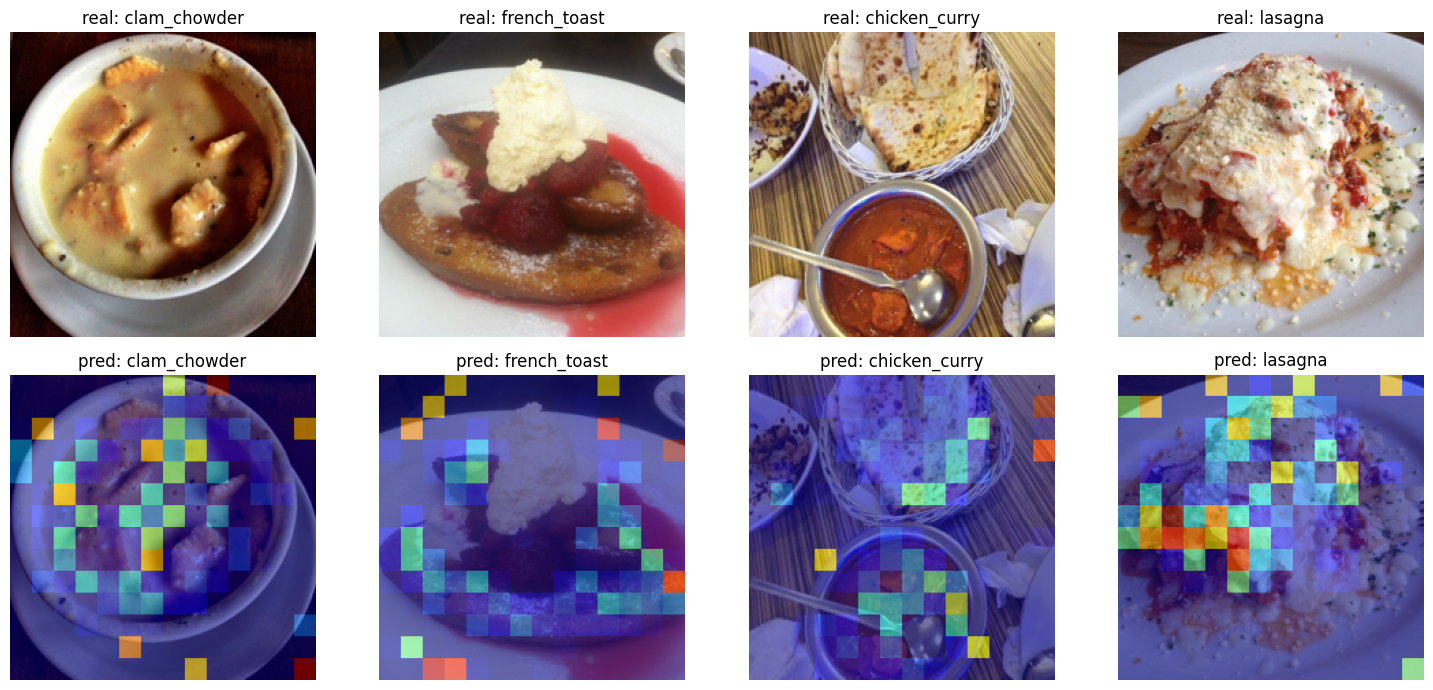

In [7]:
def mapa_atencion(img):
    x = procesador(images=img.convert("RGB"), return_tensors="pt").to(DISP)
    with torch.no_grad():
        out = vit(**x, output_attentions=True)
    att = out.attentions[-1][0].mean(0)[0, 1:].reshape(14, 14).cpu().numpy()   # CLS → 196 patches
    return CLASES[out.logits.argmax().item()], att / att.max()

fig, ax = plt.subplots(2, 4, figsize=(15, 7))
for k, i in enumerate(np.random.RandomState(0).choice(len(test), 4, replace=False)):
    img = test[int(i)]["image"].convert("RGB").resize((224, 224))
    clase, att = mapa_atencion(img)
    ax[0, k].imshow(img); ax[0, k].set_title(f"real: {CLASES[test[int(i)]['label']]}"); ax[0, k].axis("off")
    ax[1, k].imshow(img); ax[1, k].imshow(np.kron(att, np.ones((16, 16))), alpha=0.55, cmap="jet")
    ax[1, k].set_title(f"pred: {clase}"); ax[1, k].axis("off")
plt.tight_layout(); plt.savefig("resultados/atencion_vit.png", dpi=120); plt.show()

## 3. (Opcional) Afinado propio de ViT desde `google/vit-base-patch16-224-in21k`
Reproduce el procedimiento de *fine-tuning* con el `Trainer` de Hugging Face sobre un subconjunto (para que quepa en
el tiempo de Colab gratuito). Con `N_TRAIN = 75750` y 5 épocas se replica el modelo evaluado arriba (varias horas).

In [8]:
EJECUTAR_AFINADO = False
N_TRAIN = 10100   # 100 imágenes por clase aprox.

if EJECUTAR_AFINADO:
    from transformers import TrainingArguments, Trainer, DefaultDataCollator
    from torchvision.transforms import Compose, RandomResizedCrop, RandomHorizontalFlip, ToTensor, Normalize
    import evaluate
    ckpt = "google/vit-base-patch16-224-in21k"
    proc = AutoImageProcessor.from_pretrained(ckpt)
    norm = Normalize(mean=proc.image_mean, std=proc.image_std)
    tf_train = Compose([RandomResizedCrop(224), RandomHorizontalFlip(), ToTensor(), norm])
    def transformar(ej):
        ej["pixel_values"] = [tf_train(im.convert("RGB")) for im in ej["image"]]; del ej["image"]; return ej
    tr = load_dataset("ethz/food101", split="train").shuffle(seed=42).select(range(N_TRAIN)).with_transform(transformar)
    ev = test.shuffle(seed=42).select(range(2020)).with_transform(transformar)
    modelo_ft = AutoModelForImageClassification.from_pretrained(
        ckpt, num_labels=101, id2label=dict(enumerate(CLASES)), label2id={c: i for i, c in enumerate(CLASES)})
    acc = evaluate.load("accuracy")
    args = TrainingArguments("vit_food_ft", per_device_train_batch_size=32, per_device_eval_batch_size=64,
                             learning_rate=5e-5, num_train_epochs=3, warmup_ratio=0.1, fp16=True,
                             eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True,
                             metric_for_best_model="accuracy", remove_unused_columns=False, report_to=[])
    trainer = Trainer(model=modelo_ft, args=args, train_dataset=tr, eval_dataset=ev,
                      data_collator=DefaultDataCollator(),
                      compute_metrics=lambda p: acc.compute(predictions=p.predictions.argmax(-1), references=p.label_ids))
    trainer.train()
    print(trainer.evaluate())

## 4. Comparación CNN vs Transformer
Sube `resultados/metricas_cnn.json` (generado por el notebook 01) para construir la tabla del informe.

,accuracy_top1,accuracy_top5,f1_macro,parametros,ms_por_imagen_gpu
modelo,,,,,
ViT-B/16 (nateraw/food),0.8916,0.977,0.8917,85876325,9.173


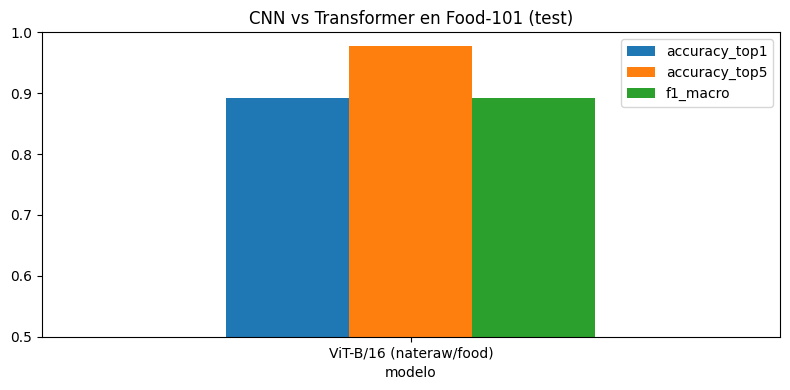

In [9]:
import pandas as pd
filas = [res_vit]
if os.path.exists("resultados/metricas_cnn.json"):
    filas.insert(0, json.load(open("resultados/metricas_cnn.json")))
df = pd.DataFrame(filas).set_index("modelo")
display(df.round(4))
df[["accuracy_top1", "accuracy_top5", "f1_macro"]].plot.bar(figsize=(8, 4), rot=0, ylim=(0.5, 1))
plt.title("CNN vs Transformer en Food-101 (test)"); plt.tight_layout()
plt.savefig("resultados/comparacion_modelos.png", dpi=120); plt.show()